In [9]:
%matplotlib inline

%reset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import skfda
import sys

from scipy import linalg
from scipy.integrate import simpson
from skfda.preprocessing.dim_reduction import FPCA
from skfda.representation.basis import BSplineBasis
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import acf, pacf
from typing import Tuple, List
from pathlib import Path

projectRoot = Path().resolve().parent

sys.path.append(str(projectRoot / 'functions'))
import fNIRSData
import funcChangePoint
import auxFuncChPt

import importlib
importlib.reload(fNIRSData)
importlib.reload(funcChangePoint)
importlib.reload(auxFuncChPt)

Nothing done.


<module 'auxFuncChPt' from '/Users/sambe/Documents/Python_Projects/FDA/functions/auxFuncChPt.py'>

Define input file/output filename (if you want to save) and the channels you wish to analyse (i,e. ROI channels)
<br> If adding more channels, the blocks of code which need to be included in a for loop are indicated below in the notebook.

In [10]:
#User defined params
location = 'GM'
agePoint = 5
numChrom = 1
firstTrial = 1
lastTrial = 25
cptSignificance = 0.001
# multiple comparison correction methods - e.g. 'b' = Bonferroni
withinChanCorrectMethod = 'b' #'h' = Bonferroni-Holm
numBasis = 21
firstSamp = -20
lastSamp = 182
channels = 'ALL' #'ROI' for ROI channels base on previous analysis; 'ALL' for all array channels
useLongRun = True #see autocorrelation test and ACF figures below!
lrCovLag = 0 #set to 0 to calculate h based on dataset size
useWildBinSeg = True

#for indexing later on
firstFunc = firstTrial-1
lastFunc = lastTrial-1


In [11]:

# Dependent on other user-defined params (above)
if numChrom == 1:
    chromName = 'HbO'
elif numChrom == 2:
    chromName = 'HbR'
else:
    chromName = 'HbT'

dataFile = str(projectRoot / 'dataRaw' / 'homer2')+str(location)+str(agePoint)+'moDataFrame.pkl'
cptFilename = str(projectRoot / 'data' / 'grpChangePointDFs' / 'ChPt')+str(location)+str(agePoint)+'mo'+str(chromName)+'FF.pkl'
volFilename = str(projectRoot / 'data' / 'grpVolRatioDFs' / 'VolRatio')+str(location)+str(agePoint)+'mo'+str(chromName)+'FF.pkl'


if channels.upper() == 'ROI':
    #(CPA) ROI channels
    channels = fNIRSData.getROI(agePoint, location)
elif channels.upper() == 'ALL':
    with open(dataFile, 'rb') as f:
        dfFull = pickle.load(f)
    channels = (np.unique(dfFull["Channel"].values)).tolist()
else:
    print("Using ALL array channels")
    with open(dataFile, 'rb') as f:
        dfFull = pickle.load(f)
    channels = (np.unique(dfFull["Channel"].values)).tolist()

Check for autocorrelation (temporal dependence) in the data, in order to see if L-R covariance should be used. 
<br> Typical threshold about 0.2-0.3 for avg. channel autocorrelation; above this --> use L-R covariance!


In [12]:
#change to code!
"""
for numChan in channels:
    
    # get functional data for this channel
    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)  

    # Compute functional autocorrelation
    acf = auxFuncChPt.computeAutocorrelation(dataMatrix, maxLag=10)

    print(acf)
"""


'\nfor numChan in channels:\n    \n    # get functional data for this channel\n    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)  \n\n    # Compute functional autocorrelation\n    acf = auxFuncChPt.computeAutocorrelation(dataMatrix, maxLag=10)\n\n    print(acf)\n'

In [13]:
"""
# Loop through each channel
for numChan in channels:
    
    # Get the functional data matrix for the channel (25 x 202)
    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)
    
    # dataMatrix is of shape (25, 202), where 25 is the number of functions (rows), and 202 is the number of time points (columns)
    
    # Transpose the dataMatrix so that we have time points (202) as rows and functions (25) as columns
    dataMatrix_transposed = dataMatrix.T  # Shape (202, 25)
    
    # Initialize arrays to store ACF and PACF results for all functions
    acf_matrix = np.zeros((25, 25))  # ACF values for each function (25 x 25)
    pacf_matrix = np.zeros((25, 25))  # PACF values for each function (25 x 25)
    
    # Loop through each pair of functions to compute the ACF and PACF
    for i in range(25):  # Function i
        # Compute ACF and PACF for function i
        series_i = dataMatrix_transposed[:, i]
        
        acf_values = acf(series_i, nlags=25, fft=True)
        pacf_values = pacf(series_i, nlags=25)
        
        # Store ACF and PACF values in the corresponding matrices
        acf_matrix[i, :] = acf_values[1:]  # Store ACF values (excluding the 0 lag)
        pacf_matrix[i, :] = pacf_values[1:]  # Store PACF values (excluding the 0 lag)

    # Plot the ACF and PACF matrices
    plt.figure(figsize=(12, 6))
    
    # Plot ACF matrix (Heatmap)
    plt.subplot(1, 2, 1)
    plt.imshow(acf_matrix, cmap='coolwarm', aspect='auto', origin='lower')
    plt.title(f"ACF for Functions (Channel {numChan})")
    plt.xlabel("Lags")
    plt.ylabel("Function Index")
    plt.colorbar(label="ACF")
    
    # Plot PACF matrix (Heatmap)
    plt.subplot(1, 2, 2)
    plt.imshow(pacf_matrix, cmap='coolwarm', aspect='auto', origin='lower')
    plt.title(f"PACF for Functions (Channel {numChan})")
    plt.xlabel("Lags")
    plt.ylabel("Function Index")
    plt.colorbar(label="PACF")
    
    plt.tight_layout()
    plt.show()
"""

'\n# Loop through each channel\nfor numChan in channels:\n    \n    # Get the functional data matrix for the channel (25 x 202)\n    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)\n    \n    # dataMatrix is of shape (25, 202), where 25 is the number of functions (rows), and 202 is the number of time points (columns)\n    \n    # Transpose the dataMatrix so that we have time points (202) as rows and functions (25) as columns\n    dataMatrix_transposed = dataMatrix.T  # Shape (202, 25)\n    \n    # Initialize arrays to store ACF and PACF results for all functions\n    acf_matrix = np.zeros((25, 25))  # ACF values for each function (25 x 25)\n    pacf_matrix = np.zeros((25, 25))  # PACF values for each function (25 x 25)\n    \n    # Loop through each pair of functions to compute the ACF and PACF\n    for i in range(25):  # Function i\n        # Compute ACF and PACF for function i\n        series_i = dataMatrix_transposed[:, i]\n        \n      

In [14]:
columnList = ['Channel',
'Chromophore',
'Recursion Level',
'First Trial',
'Last Trial',
'Change Point',
'Max. T_N',
'p-value']

dfChangePoints = pd.DataFrame(columns = columnList)

gridPoints = np.arange(firstSamp, lastSamp, 1) # for func. data

allPValues = []  # initialise storage all p-values for across-channel correction
globalIndex = 0 #for dfChangePoints indexing

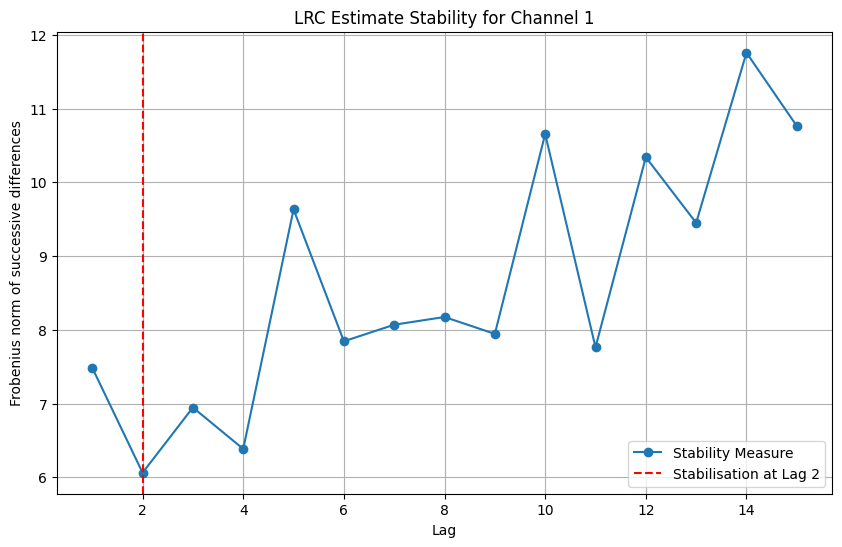

Progress: 2.9%


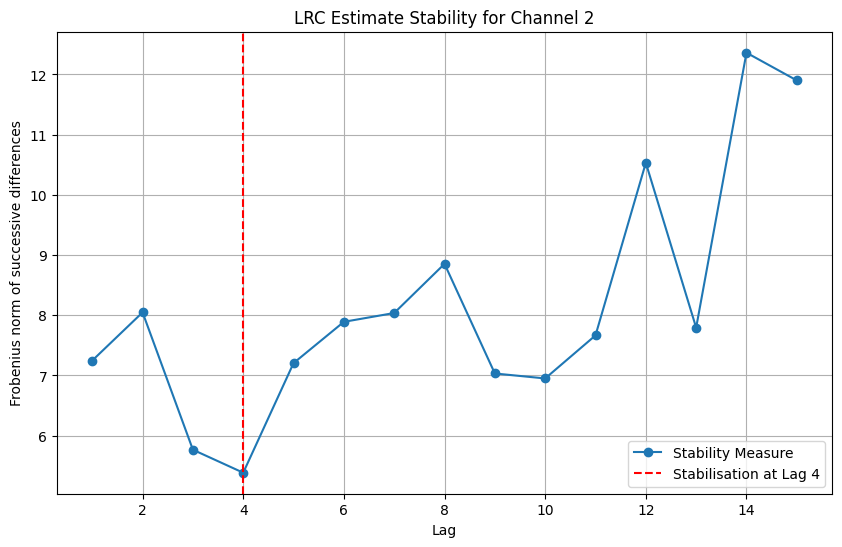

Progress: 5.9%


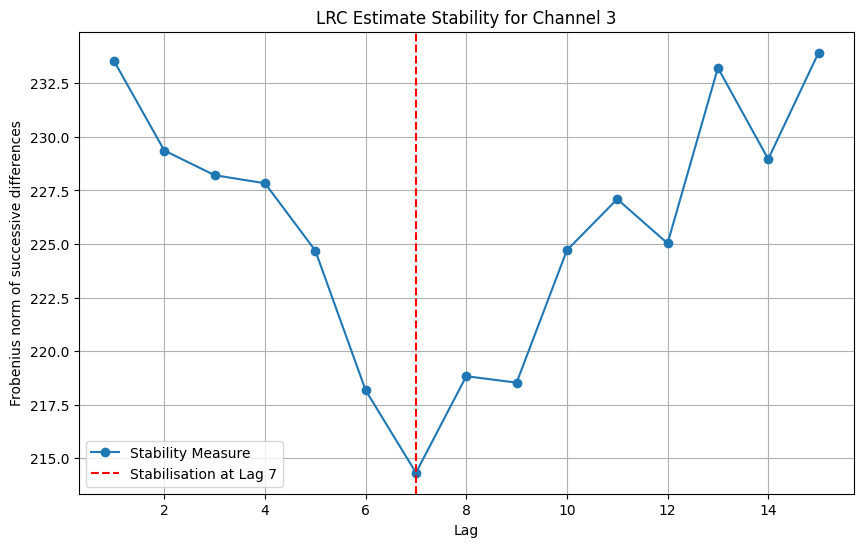

Progress: 8.8%


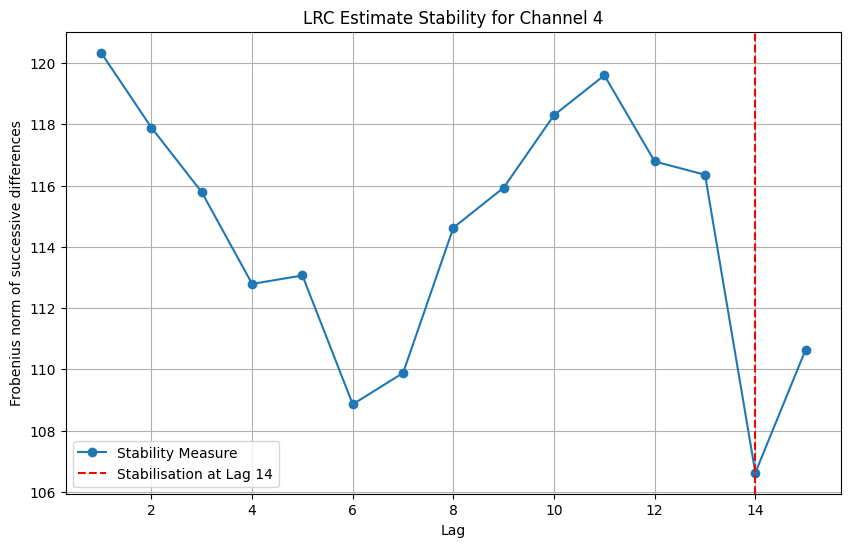

Progress: 11.8%


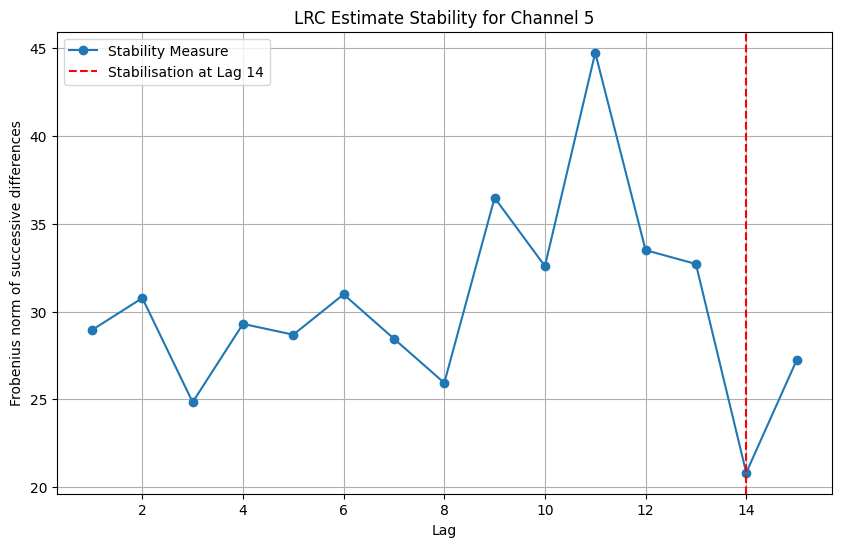

Progress: 14.7%


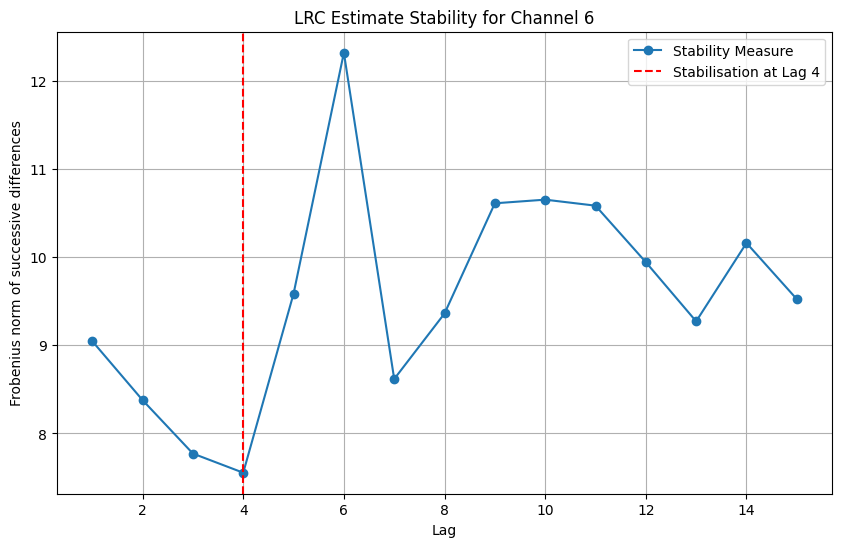

Progress: 17.6%


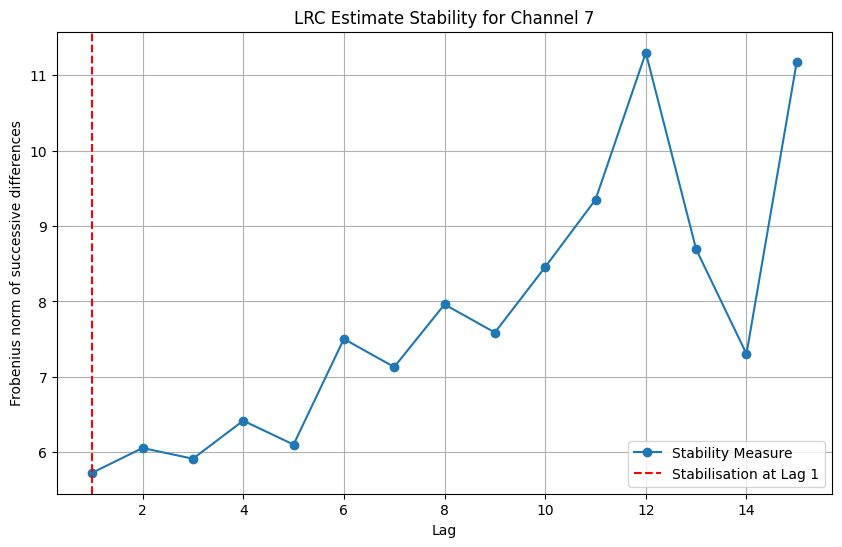

Progress: 20.6%


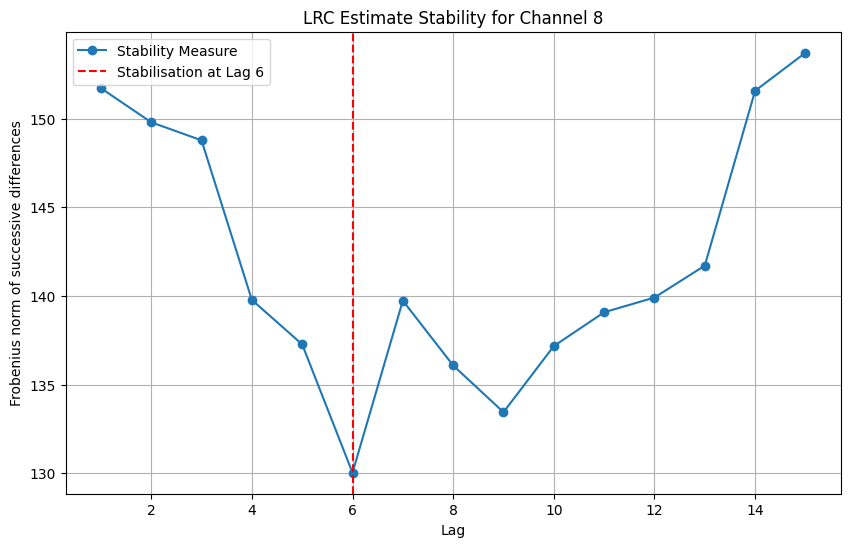

Progress: 23.5%


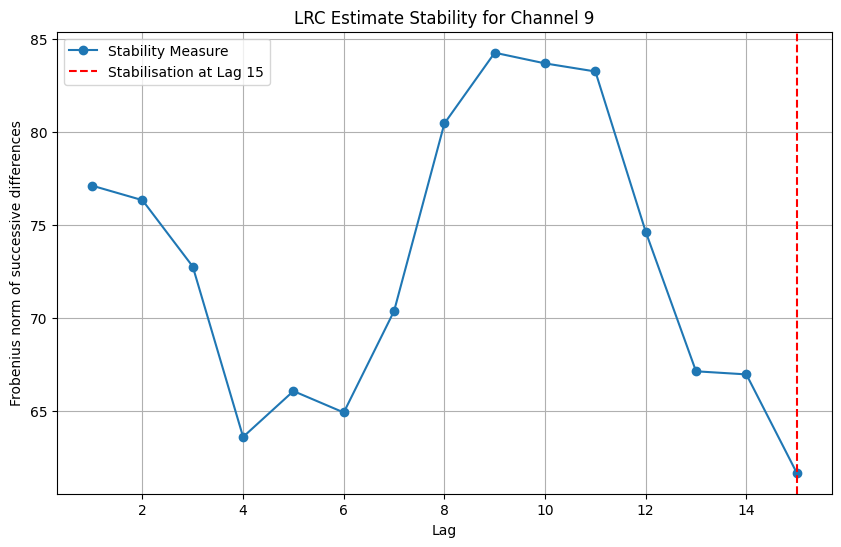

Progress: 26.5%


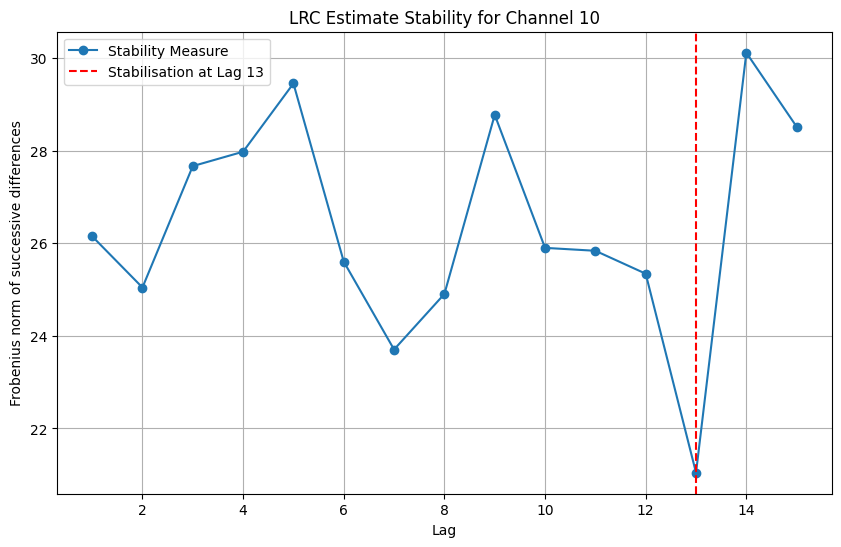

Progress: 29.4%


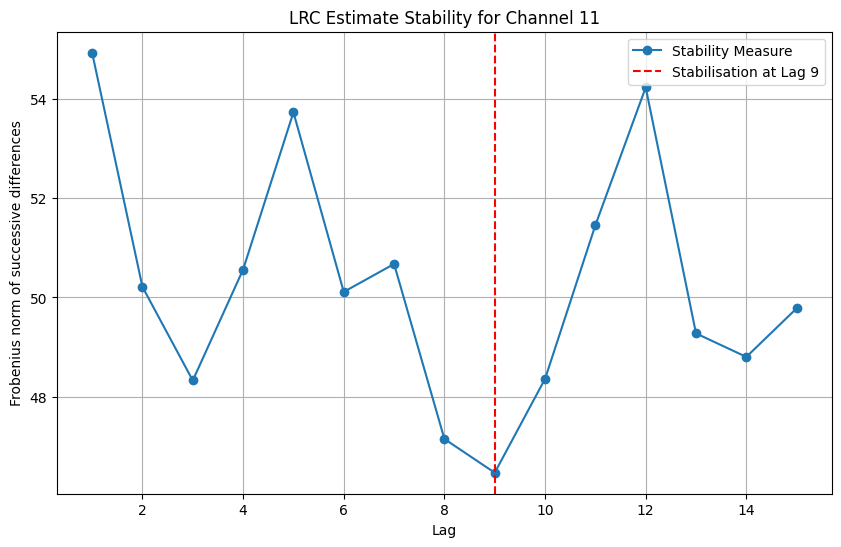

Progress: 32.4%


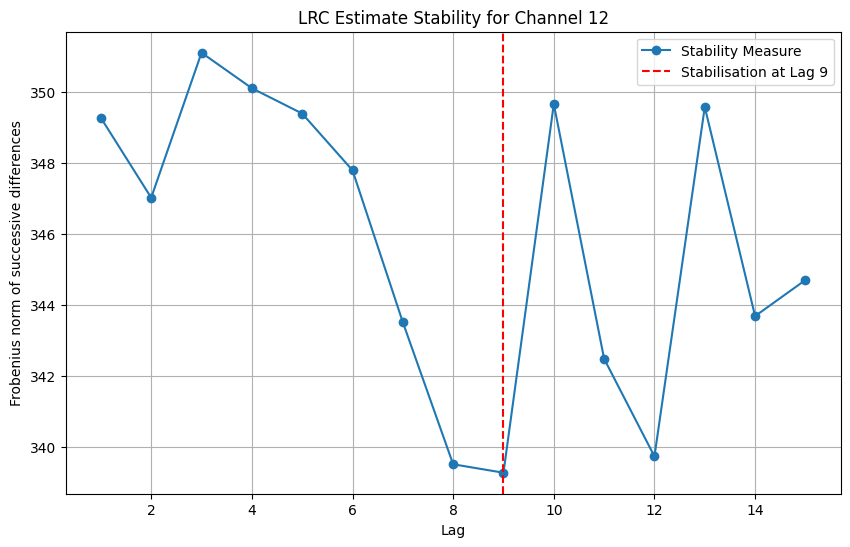

Progress: 35.3%


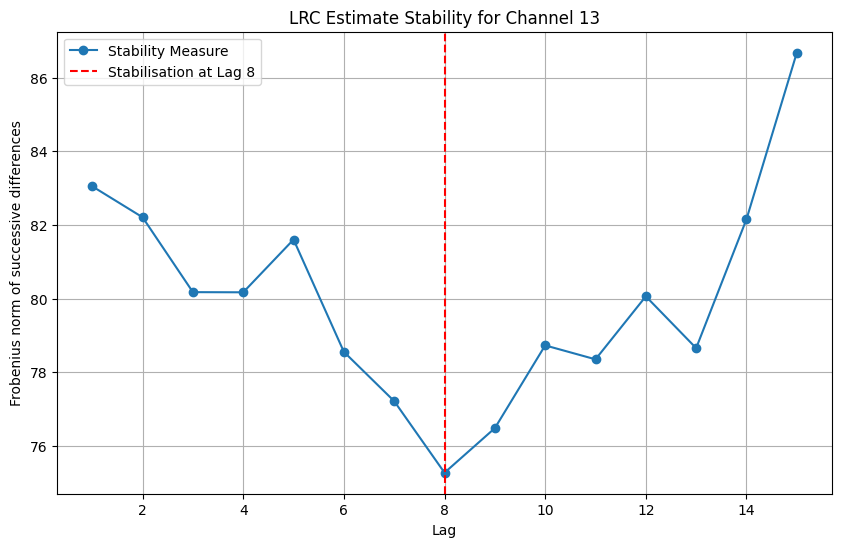

Progress: 38.2%


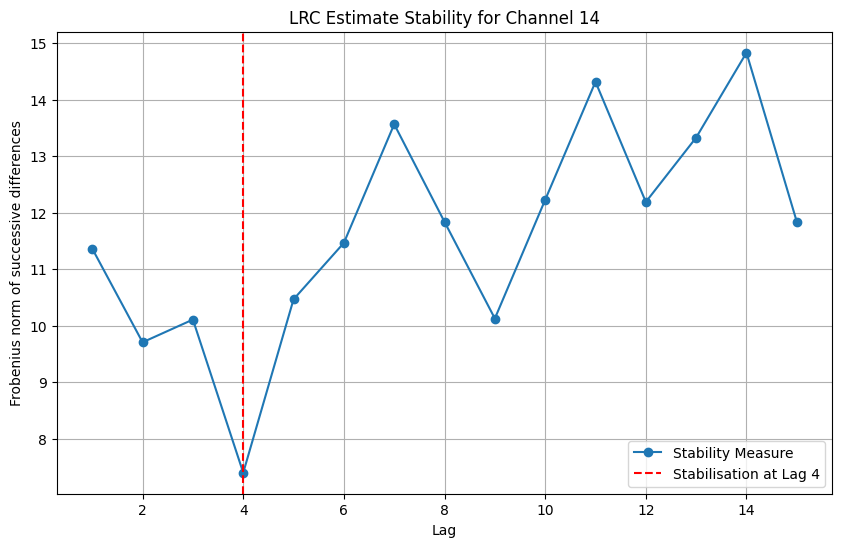

Progress: 41.2%


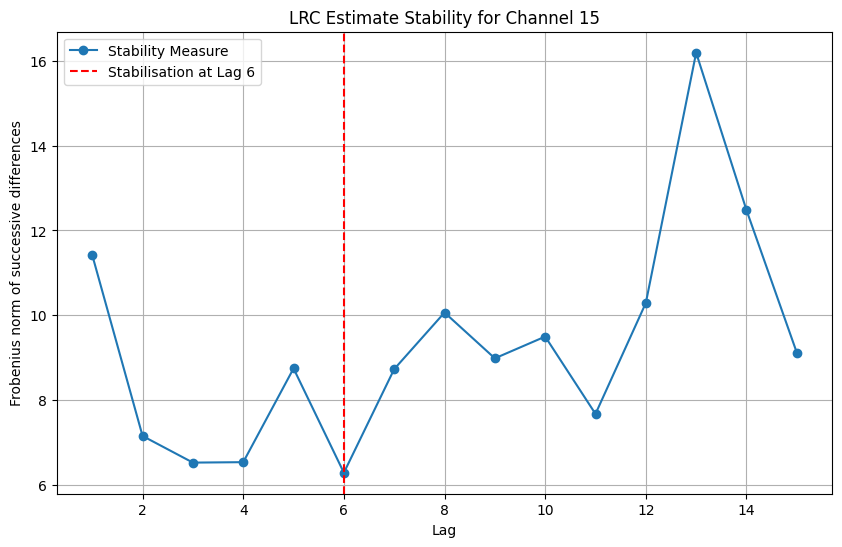

Progress: 44.1%


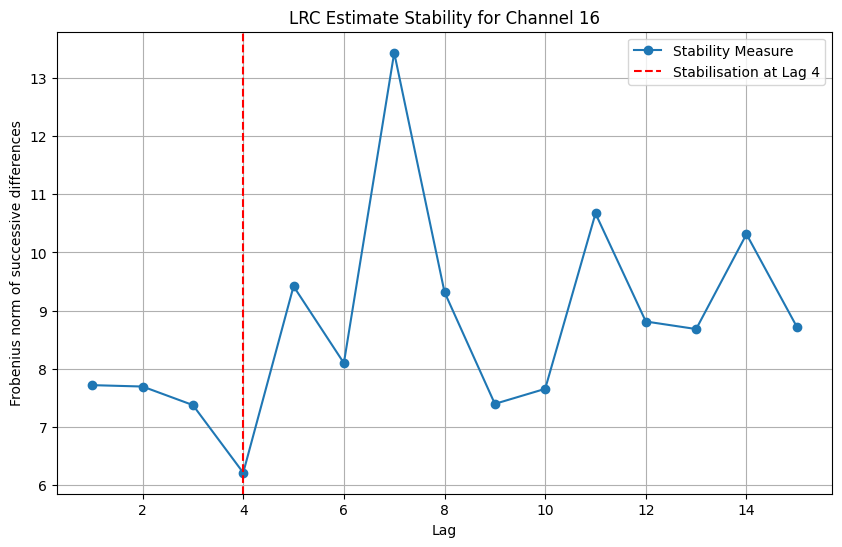

Progress: 47.1%


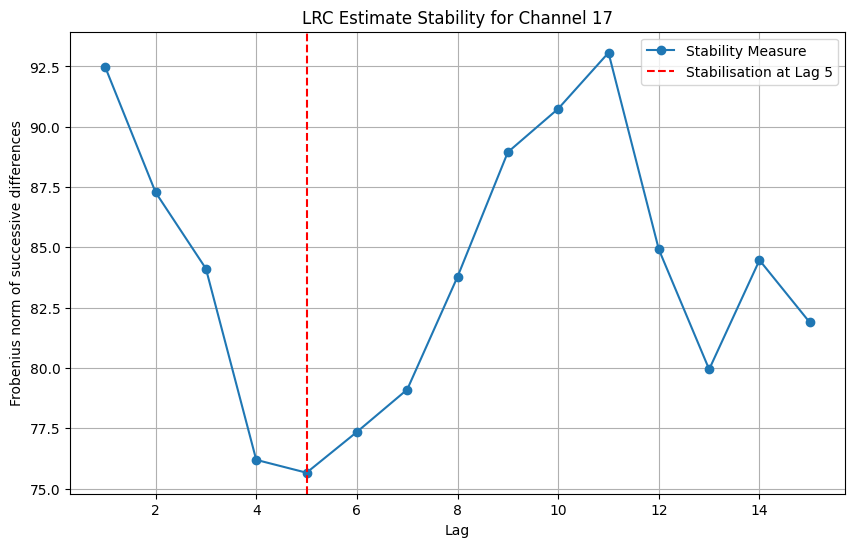

Progress: 50.0%


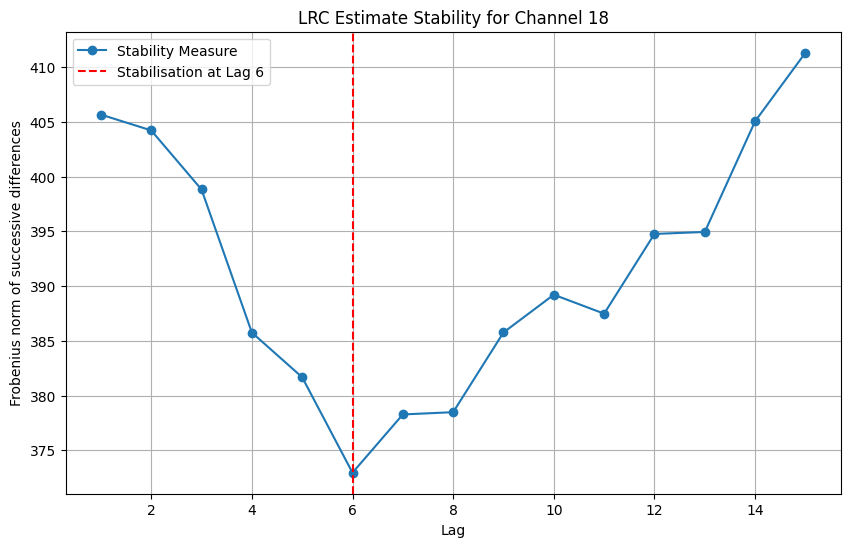

Progress: 52.9%


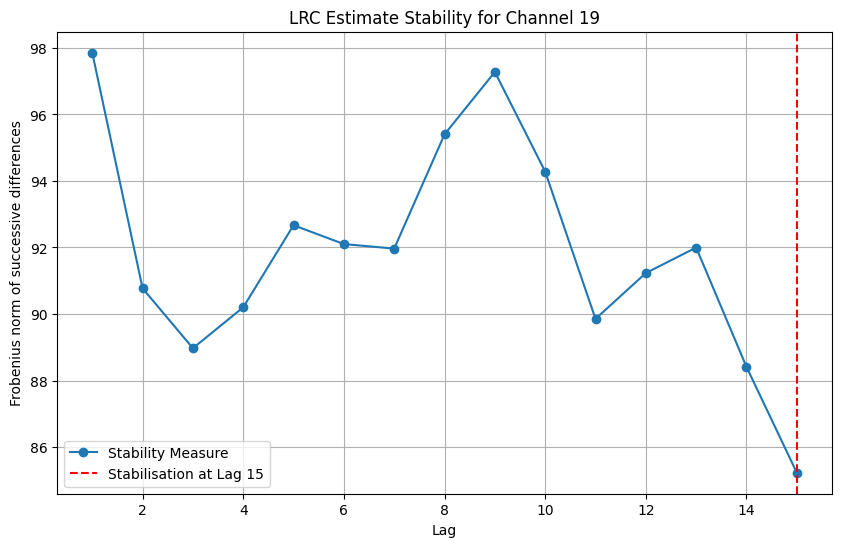

Progress: 55.9%


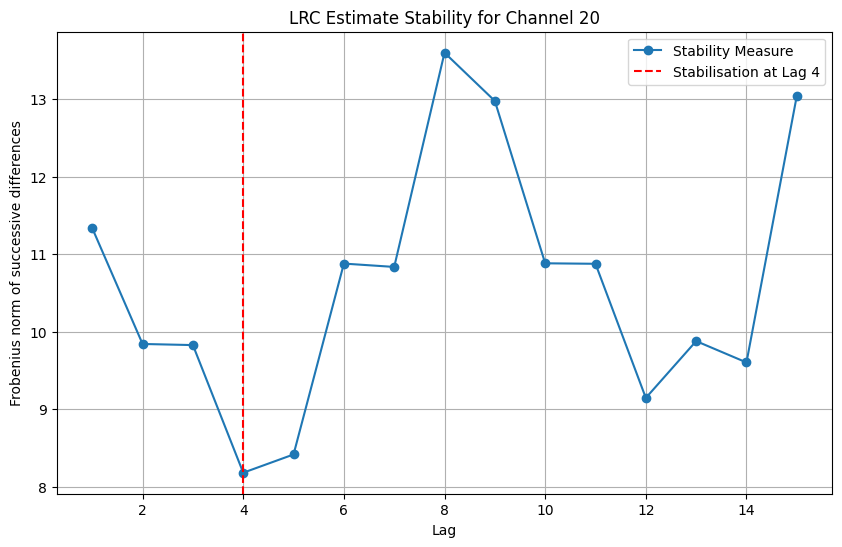

Progress: 58.8%


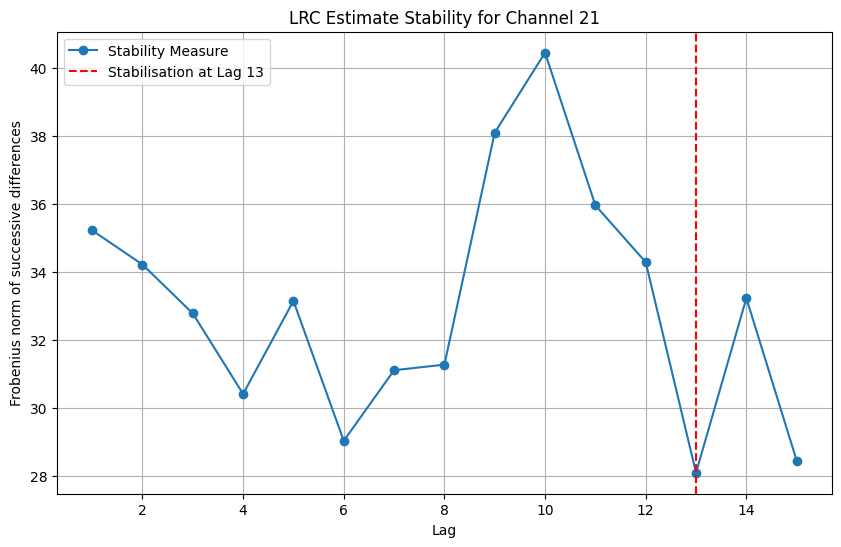

Progress: 61.8%


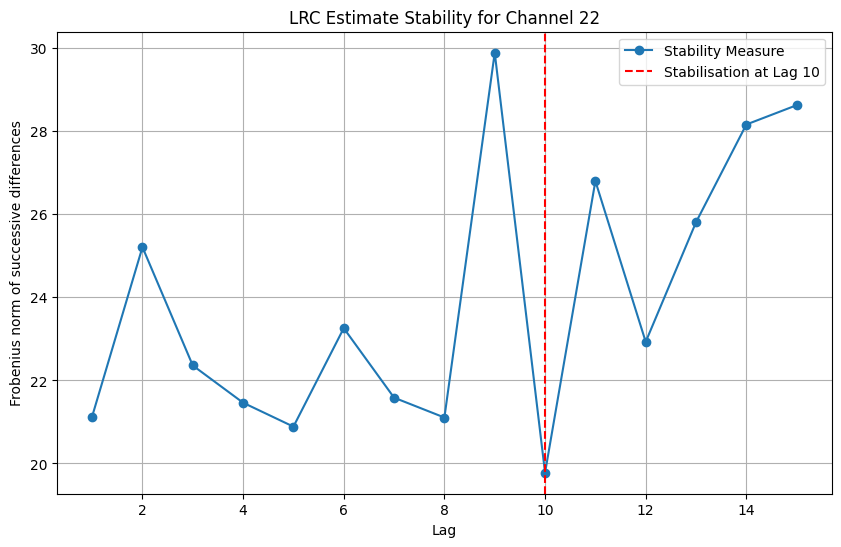

Progress: 64.7%


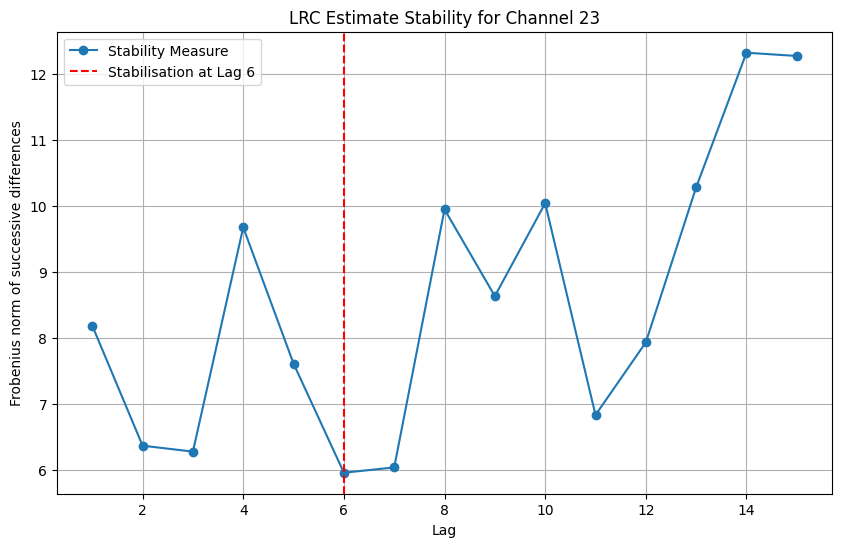

Progress: 67.6%


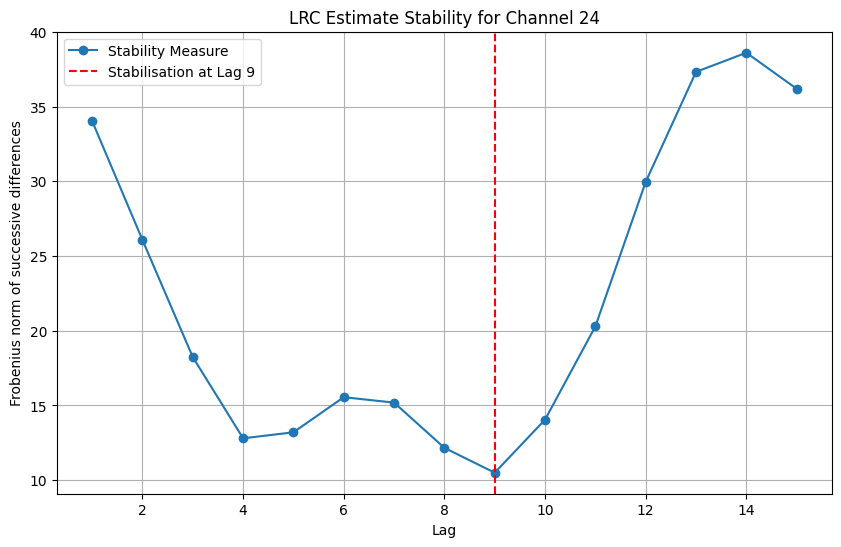

Progress: 70.6%


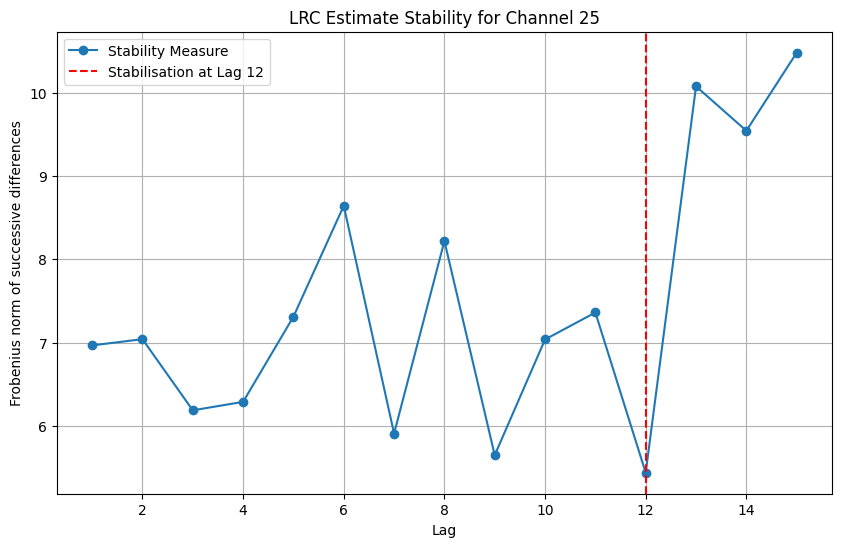

Progress: 73.5%


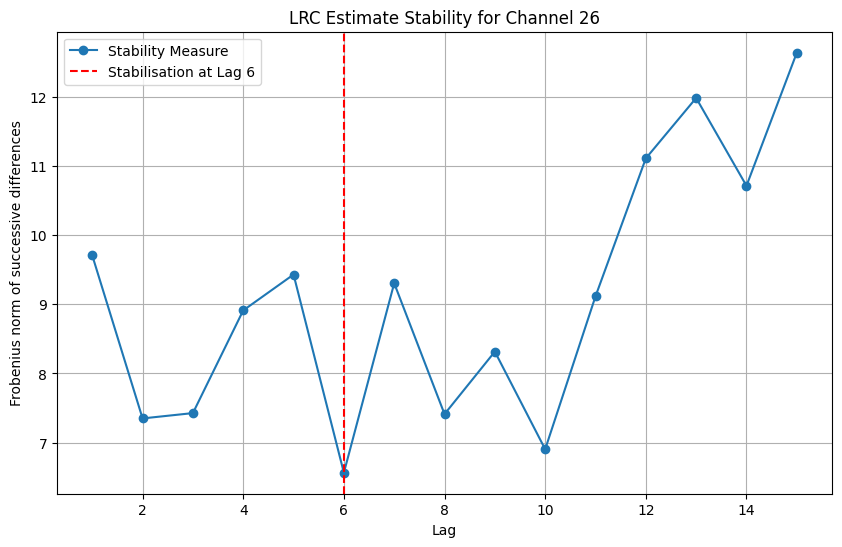

Progress: 76.5%


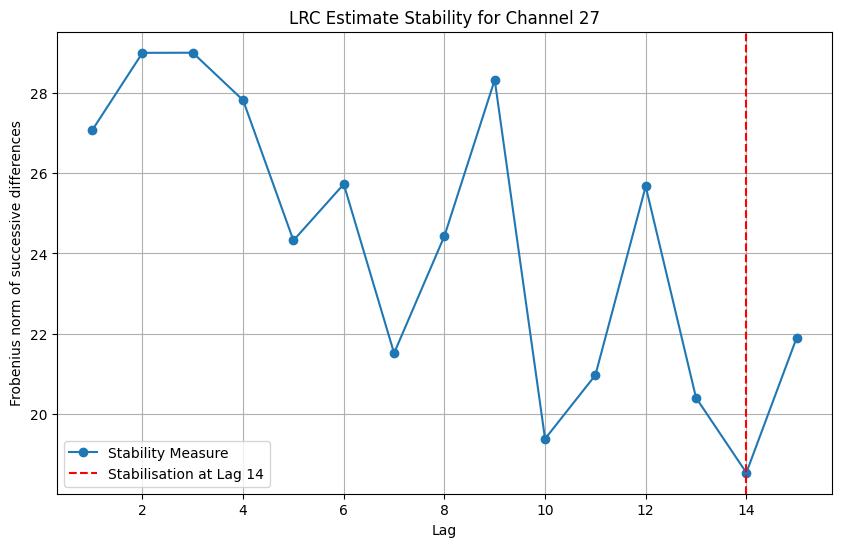

Progress: 79.4%


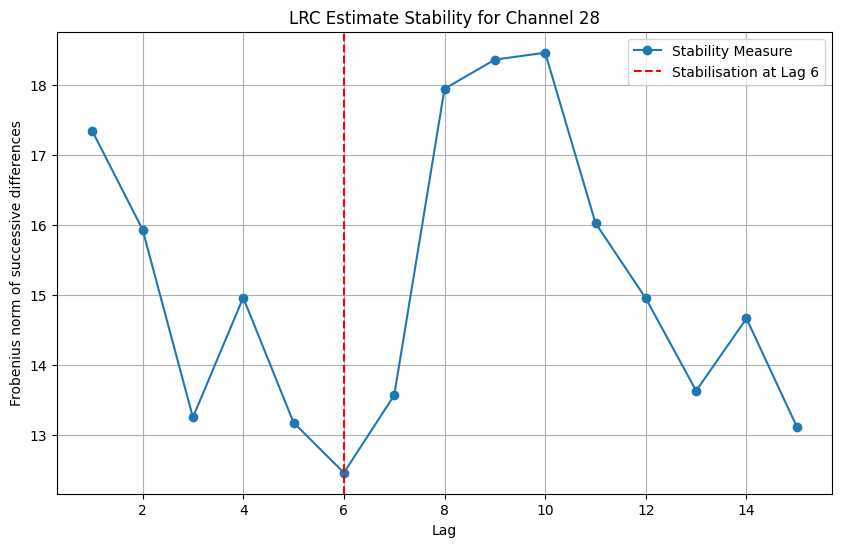

Progress: 82.4%


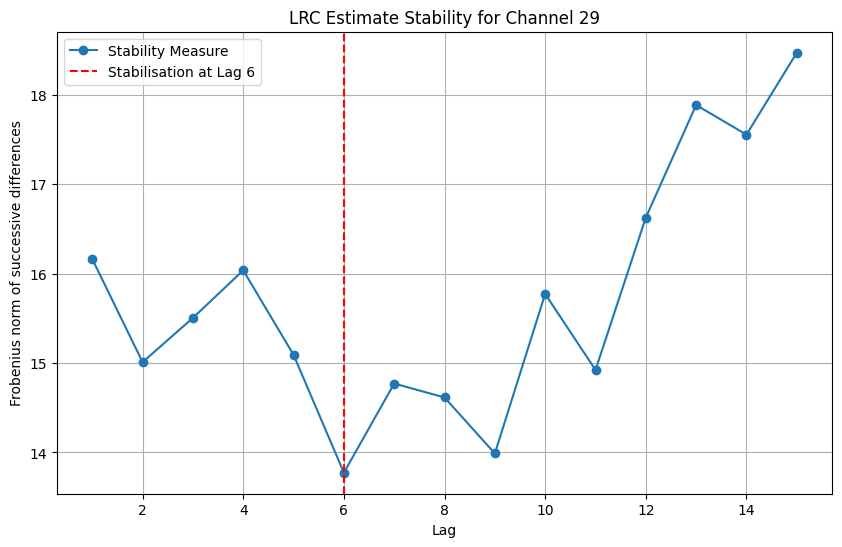

Progress: 85.3%


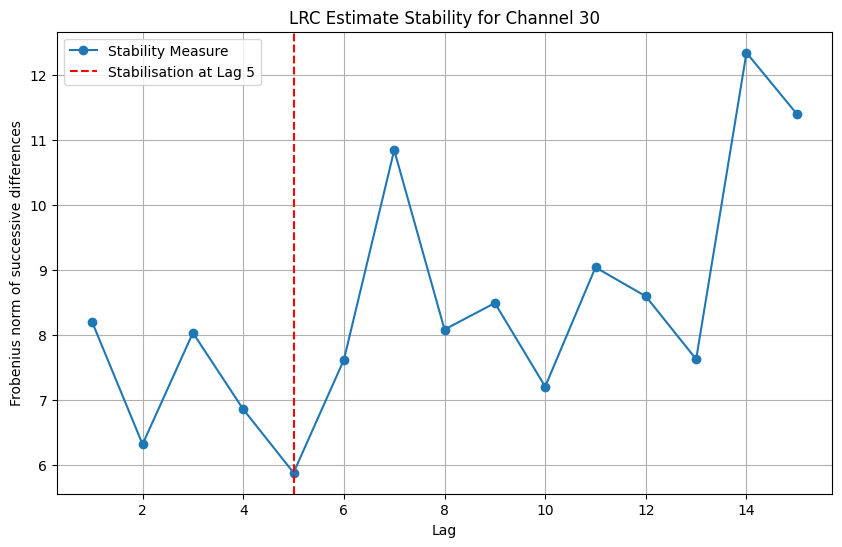

Progress: 88.2%


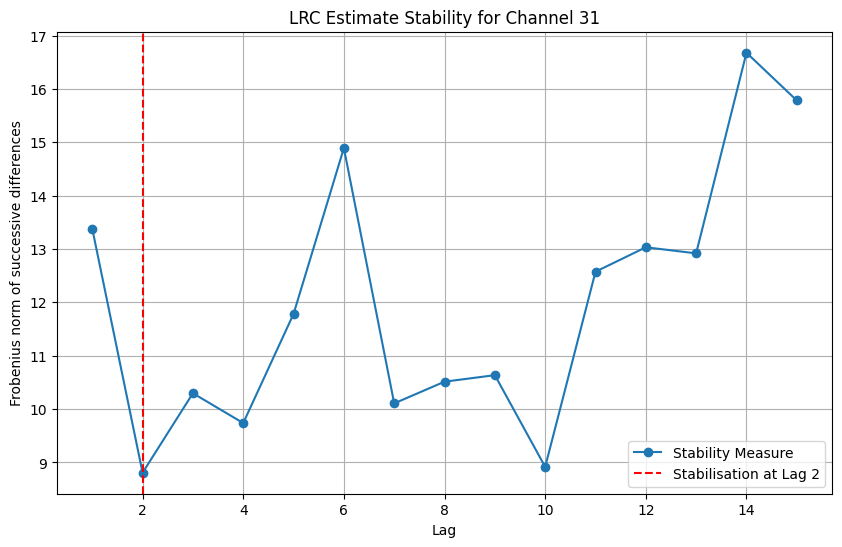

Progress: 91.2%


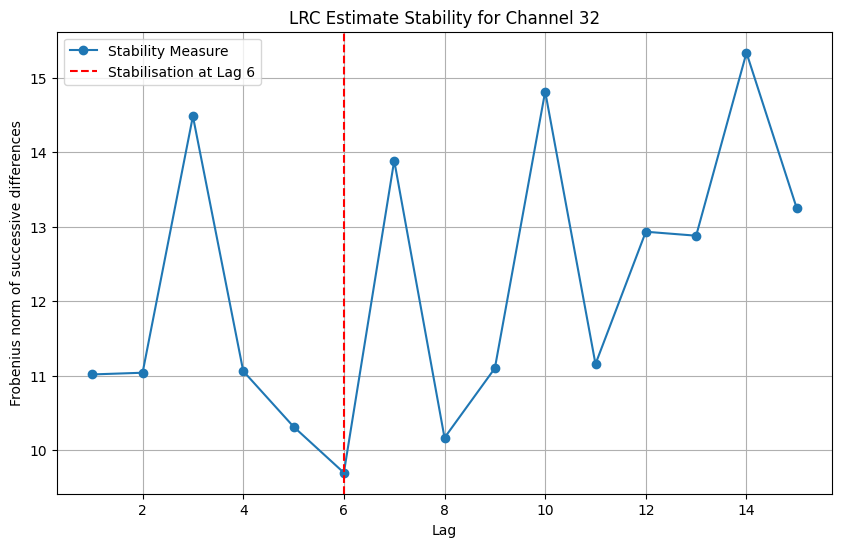

Progress: 94.1%


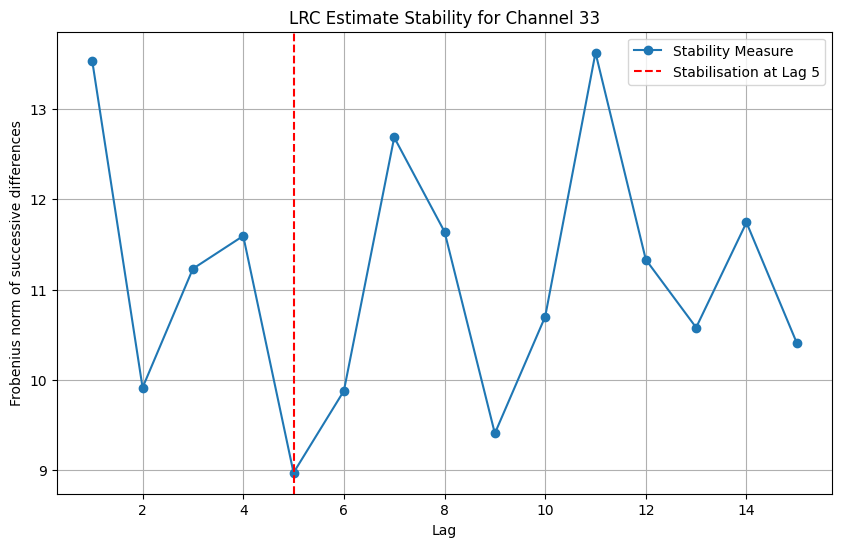

Progress: 97.1%


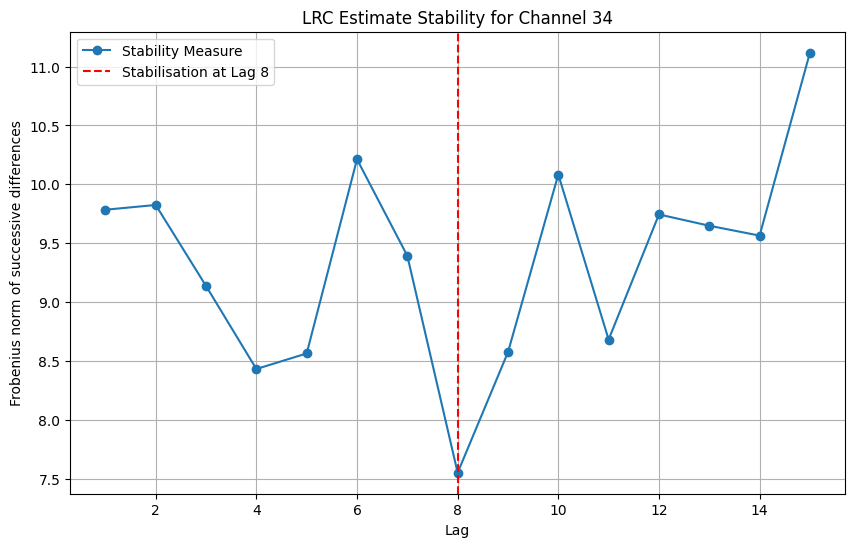

Progress: 100.0%


NameError: name 'math' is not defined

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import linalg
import seaborn as sns
from typing import Tuple, List, Dict

def normaliseCoefficients(coefficients: np.ndarray) -> np.ndarray:
    """
    Normalise coefficients by dividing each column by its standard deviation.

    Parameters:
    -----------
    coefficients : np.ndarray
        Coefficients matrix.

    Returns:
    --------
    np.ndarray
        Normalised coefficients.
    """
    return coefficients / np.std(coefficients, axis=0, keepdims=True)

def computeLrcAtLag(fdObj, maxLag: int) -> Tuple[np.ndarray, List[float]]:
    """
    Compute long-run covariance estimates for increasing lags.

    Parameters:
    -----------
    fdObj : FDataBasis
        Functional data object with B-spline basis.
    maxLag : int
        Maximum lag to compute.

    Returns:
    --------
    lrcEstimates : np.ndarray
        Array of LRC matrices for each lag.
    stabilityMeasures : List[float]
        Frobenius norms of differences between successive estimates.
    """
    coef = normaliseCoefficients(fdObj.coefficients)
    nObs, nBasis = coef.shape
    lrcEstimates = np.zeros((maxLag + 1, nBasis, nBasis))
    stabilityMeasures = []

    # Compute autocovariance matrices up to maxLag
    for lag in range(maxLag + 1):
        # Base autocovariance (lag 0)
        if lag == 0:
            autoCov = np.cov(coef.T)
            lrcEstimates[0] = autoCov
            stabilityMeasures.append(0)
            continue

        # Compute autocovariance at current lag
        lagCov = np.zeros((nBasis, nBasis))
        for i in range(nObs - lag):
            lagCov += np.outer(coef[i], coef[i + lag])
        lagCov /= (nObs - lag)

        # Update LRC estimate
        lrcEstimates[lag] = lrcEstimates[lag-1] + (lagCov + lagCov.T)

        # Compute stability measure
        diffNorm = linalg.norm(lrcEstimates[lag] - lrcEstimates[lag-1], 'fro')
        stabilityMeasures.append(diffNorm)

    return lrcEstimates, stabilityMeasures

def plotLrcStability(stabilityMeasures: List[float], maxLag: int, channel: int = None, stabilisationLag: int = None):
    """
    Plot stability measures for visual inspection and highlight the stabilisation point.

    Parameters:
    -----------
    stabilityMeasures : List[float]
        List of stability measures.
    maxLag : int
        Maximum lag used.
    channel : int, optional
        Channel number for plot title. If None, assumes single channel plot.
    stabilisationLag : int, optional
        The lag at which the stabilization occurs. If None, it will be computed automatically.
    """
    plt.figure(figsize=(10, 6))
    lags = range(1, maxLag + 1)
    plt.plot(lags, stabilityMeasures[1:], '-o', label='Stability Measure')
    
    if stabilisationLag is not None:
        plt.axvline(stabilisationLag, color='red', linestyle='--', label=f'Stabilisation at Lag {stabilisationLag}')
    
    plt.xlabel('Lag')
    plt.ylabel('Frobenius norm of successive differences')
    title = 'LRC Estimate Stability'
    if channel is not None:
        title += f' for Channel {channel}'
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.show()

def plotCombinedLrcStability(stabilityMeasuresDict, maxLag, stabilisationLags):
    """
    Plot stability measures for all channels in a single figure with subplots.
    
    Parameters:
    -----------
    stabilityMeasuresDict : Dict[int, List[float]]
        Dictionary mapping channel numbers to their stability measures.
    maxLag : int
        Maximum lag used.
    stabilisationLags : Dict[int, int]
        Dictionary mapping channel numbers to their corresponding stabilisation lag.
    """
    numChannels = len(stabilityMeasuresDict)
    numCols = min(4, numChannels)  # Max 4 columns
    numRows = math.ceil(numChannels / numCols)
    
    fig, axes = plt.subplots(numRows, numCols, figsize=(4*numCols, 3*numRows), sharex=True, sharey=True)
    axes = np.array(axes).reshape(-1)  # Flatten in case of single row/column
    
    for idx, (channel, measures) in enumerate(stabilityMeasuresDict.items()):
        ax = axes[idx]
        stabilisationLag = stabilisationLags.get(channel, None)
        lags = range(1, min(len(measures), maxLag + 1))
        ax.plot(lags, measures[1:len(lags)+1], '-o', label=f'Channel {channel}')
        
        if stabilisationLag is not None:
            ax.axvline(stabilisationLag, color='red', linestyle='--', label=f'Stabilisation at Lag {stabilisationLag}')
        
        ax.set_title(f'Channel {channel}')
        ax.grid(True)
        ax.legend()
    
    # Hide empty subplots
    for j in range(idx + 1, len(axes)):
        fig.delaxes(axes[j])
    
    fig.supxlabel('Lag')
    fig.supylabel('Frobenius norm of successive differences')
    fig.suptitle('LRC Estimate Stability Across Channels')
    plt.tight_layout()
    plt.show()



def plotStabilisationDistribution(stabilisationLags: Dict[int, int]):
    """
    Generate and plot the distribution of stabilisation points (lags) across all channels.
    
    Parameters:
    -----------
    stabilisationLags : Dict[int, int]
        Dictionary mapping channel numbers to their corresponding stabilisation lag.
    """
    # Extract stabilisation lags
    stabilisationLagValues = list(stabilisationLags.values())

    # Plot histogram for stabilisation lags
    plt.figure(figsize=(10, 6))
    # Plot histogram
    n, bins, patches = plt.hist(stabilisationLagValues, bins=range(1, max(stabilisationLagValues) + 2), edgecolor='black', alpha=0.7)

    # Adjust x-axis labels to be centered on bars
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    plt.xticks(bin_centers, bin_centers.astype(int))
    
    plt.xlabel('Lag (Stabilisation Point)')
    plt.ylabel('Frequency')
    plt.title('Distribution of Stabilisation Lags Across Channels')
    plt.grid(True)
    plt.show()

    # plot Kernel Density Estimate (KDE) for smoother distribution
    plt.figure(figsize=(10, 6))
    sns.kdeplot(stabilisationLagValues, shade=True, color="b")
    plt.xlabel('Lag (Stabilisation Point)')
    plt.ylabel('Density')
    plt.title('Kernel Density Estimate of Stabilisation Lags Across Channels')
    plt.grid(True)
    plt.show()


def analyseLrcStability(fdObj, maxLag: int = 10, channel: int = None):
    """
    Main function to analyse LRC stability, identify the stabilisation point, and highlight it on plots.

    Parameters:
    -----------
    fdObj : FDataBasis
        Functional data object.
    maxLag : int
        Maximum lag to analyse (default: 10).
    channel : int, optional
        Channel number for plotting. If None, assumes single channel analysis.
    """
    # Warn if maxLag is too large relative to sample size
    nObs = fdObj.coefficients.shape[0]
    if maxLag > nObs // 3:
        print(f"Warning: maxLag ({maxLag}) is large relative to sample size ({nObs})")

    # Compute LRC estimates and stability measures
    lrcEstimates, stabilityMeasures = computeLrcAtLag(fdObj, maxLag)

    # Find the stabilisation point (lag with minimum stability measure)
    stabilisationLag = np.argmin(stabilityMeasures[1:]) + 1

    # Plot stability measures for individual channel and highlight stabilisation point
    plotLrcStability(stabilityMeasures, maxLag, channel, stabilisationLag)

    # Return summary statistics, including stabilisation lag
    return {
        'lrcEstimates': lrcEstimates,
        'stabilityMeasures': stabilityMeasures,
        'meanChange': np.mean(stabilityMeasures[1:]),
        'maxChange': np.max(stabilityMeasures[1:]),
        'stabilisationLag': stabilisationLag
    }

# Modified analysis loop with stabilisation lag tracking
stabilityMeasuresDict = {}
stabilisationLags = {}

for numChan in channels:
    # get functional data for this channel
    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)                                      
    fd = skfda.FDataGrid(data_matrix=dataMatrix, grid_points=gridPoints)
    basis = BSplineBasis(n_basis=numBasis)
    fdObj = fd.to_basis(basis)

    lag = min(10, fdObj.coefficients.shape[0]//3)
    
    results = analyseLrcStability(fdObj, 15, channel=numChan)
    stabilityMeasuresDict[numChan] = results['stabilityMeasures']
    stabilisationLags[numChan] = results['stabilisationLag']

    print('Progress: '+str(round((channels.index(numChan)+1) / len(channels) * 100, 1))+'%')

# After all channels are processed, create the combined plots
plotCombinedLrcStability(stabilityMeasuresDict, 20, stabilisationLags)
plotStabilisationDistribution(stabilisationLags)
